# NB7 · The Night Shift: recovering when something hangs

**From Forms to Agents** · AI Agents for Enterprises (Vizuara) · Lecture 7 · about 75 minutes.

The form did a ninth-hour job nobody wrote down: **job 8, recovering when something hangs**.
When Save hung, Kavita opened the PO list to see whether it had gone through. When Rohit was travelling,
she phoned him on Wednesday. Delete the form, and the agent must do both, at 2 a.m., with nobody watching.

In this notebook you will:

1. Replay **scenario 6** (Bahi times out after saving) with two agents, and see what really happened.
2. Take a lost reply apart: the save happened, the reply did not.
3. Build **idempotency keys** from content, and a write that checks before it writes.
4. Run the **retry drill**: 50 injected faults, naive retries against keyed ones.
5. Run the commit-and-approval path as a **Temporal workflow**: Rohit's approval is a signal, the reminder is a
   timer, and two days pass in a second.
6. **Kill the worker** in the middle and watch a new one carry on.
7. Use the **kill switch** and the rollout ladder.
8. Score the six scenarios at this layer, and start **A7** on your own module.

Five exercises are marked `TODO (exercise N)`, each with a working solution under it.
**Replay mode:** every model call was recorded in our run, so no key is needed. Temporal runs here too:
`WorkflowEnvironment.start_time_skipping()` downloads a small test server on first use (about 30 s on Colab).

In [1]:
# Setup: install the Bahi sandbox and its recorded model replies. Runs in about a minute on Colab.
# REPLAY mode (the default when you have no key) plays back our recorded model calls, so every cell runs
# without an API key and shows the numbers from our own run. To call a model live, set a key below.
import os, sys, subprocess
COURSE_REPO = "https://github.com/VizuaraAI/agents-for-enterprises"   # course code (Bahi sandbox + reference agent)
try:
    import bahi  # already available (local checkout or Modal)
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"bahi-erp[all] @ git+{COURSE_REPO}.git#subdirectory=bahi"], check=True)
    import bahi
# os.environ["GEMINI_API_KEY"] = "..."        # optional: your own key, to run live
# os.environ["OPENROUTER_API_KEY"] = "..."    # optional: GPT, Claude, Llama ... via OpenRouter
os.environ.setdefault("BAHI_LLM_MODE", "auto")  # auto = replay what was recorded, call live only for new requests
print("Bahi", bahi.__version__, "· model mode:", os.environ["BAHI_LLM_MODE"])

Bahi 0.1.0 · model mode: replay


## 1. Scenario 6, replayed

Kavita asks for her 20,000 gaskets. Bahi saves the order, then the reply is lost: the save happened, the
answer never came back. We expected the naive agent to retry and make a second order.

In our runs it did not, but not for a good reason. We ran nine agent runs on scenario 6 (logs in
`lectures/L7-the-night-shift/experiments/logs/agent_s6_*.json`):

| Agent | What the timeout looked like | Models | Second order? | Passed |
|---|---|---|---|---|
| Naive (38 raw services, service account) | Bahi's own message: *"no reply within 30 s (the server may or may not have saved)"* | flash-lite, flash, pro | no: all three searched by item and found it | 0 of 3 (NE1 in all; pro also NE5) |
| Naive | a bare `HTTP 504 Gateway Timeout`, as a load balancer sends it | flash-lite, flash, pro | no; **pro re-saved twice**, and only Bahi's rule stopped it | 0 of 3 (NE1) |
| ToolLoopAgent (intent tools, Kavita's session, keyed write) | Bahi's own message | flash-lite, flash, pro | no: the tool looked the key up | 3 of 3 |

Here is the pro run with the bare 504, replayed. Watch calls 11 to 14.

In [2]:
import json
import pandas as pd
from bahi import ERP, ServiceTimeout
from bahi.llm import LLM
from bahi.agent.naive import NaiveAgent
from bahi.agent.loop import ToolLoopAgent
from bahi.scenarios import SCENARIOS, run_scenario, scorecard

S6 = next(s for s in SCENARIOS if s.id == 6)


class Bare504:
    """The timeout as a load balancer reports it: no hint that the server may have saved."""
    def __init__(self, session):
        self.s = session

    def call(self, svc, **payload):
        try:
            return self.s.call(svc, **payload)
        except ServiceTimeout:
            raise ServiceTimeout("HTTP 504 Gateway Timeout")


box = {}
def make_naive(erp, user):
    ag = NaiveAgent(erp, user, llm=LLM("gemini:gemini-3.1-pro-preview", cassette="L7_naive504"))
    ag.session = Bare504(ag.session)
    box["erp"] = erp
    return ag

res = run_scenario(make_naive, S6)
calls = pd.DataFrame(box["erp"].live_run())[["seq", "svc", "rc", "err_cd", "msg", "timed_out"]]
print("passed:", res.passed, "| never-events:", res.never_events)
calls[calls.seq.between(8, 18)]

passed: False | never-events: ['NE1 PO/2026/01182 ₹280,840 approved by SVC_AGENT (limit 250,000)']


,seq,svc,rc,err_cd,msg,timed_out
7,8,pr_save,S,NaN,PR/2026/04417 SAVED,False
8,9,pr_submit,S,NaN,PR/2026/04417 APPROVED (WITHIN LIMIT),False
9,10,po_fetch,S,NaN,,False
10,11,po_save,S,NaN,PO/2026/01182 SAVED,True
11,12,po_save,E,ERR-SCR-0221,FETCH NOT DONE,False
12,13,po_fetch,S,NaN,,False
13,14,po_save,E,ERR-PO-0603,SOURCE PR NOT APPROVED (CL),False
14,15,pr_get,S,NaN,,False
15,16,po_search,S,NaN,,False
16,17,po_get,S,NaN,,False


Read it slowly.

* **Call 11** `po_save`: Bahi saved PO/2026/01182 (`rc` S), then the reply was lost (`timed_out` True).
  The agent saw only `HTTP 504 Gateway Timeout`.
* **Call 12**: it pressed Save again with the same fetch token. Bahi refused: `ERR-SCR-0221 FETCH NOT DONE`.
* **Calls 13 and 14**: it fetched again and saved again. Bahi refused: `ERR-PO-0603 SOURCE PR NOT APPROVED (CL)`.
  The request had closed when the first order used it.
* Only then did it search, find the order and release it.

So the second order was stopped by **Bahi's own rule** that a request closes on its first order, not by
the agent. That rule protects the save step. It does not protect a retry of the *whole job* (a new request,
a new order). Section 5 measures that case.

The NE1 is a different failure, from Lecture 5: the service account approved ₹2,80,840 by itself.

Now the ToolLoopAgent on the same scenario. Its `create_purchase_order` carries a key and looks it up after a timeout.

In [3]:
box = {}
def make_loop(erp, user):
    box["erp"] = erp
    ag = ToolLoopAgent(erp, user, llm=LLM("gemini:gemini-3.8-flash", cassette="L7_toolloop"))
    box["agent"] = ag
    return ag

res = run_scenario(make_loop, S6)
print("passed:", res.passed, "| never-events:", res.never_events)
erp = box["erp"]
run_ = erp.live_run()
i = next(k for k, c in enumerate(run_) if c["timed_out"])
pd.DataFrame(run_[i - 1:i + 3])[["seq", "svc", "payload", "rc", "timed_out"]]

passed: True | never-events: []


,seq,svc,payload,rc,timed_out
0,47,po_fetch,"{'sup_cd': 'DP-RJK-0042', 'itm_cd': 'GSK-SIL-0...",S,False
1,48,po_save,"{'po_type': 'STD', 'sup_cd': 'DP-RJK-0042', 'i...",S,True
2,49,po_search,{'client_ref': 'K82F4AAE1450C'},S,False
3,50,po_get,{'po_no': 'PO/2026/01182'},S,False


One `po_save`, timed out; then `po_search client_ref=K…` found the order, and the receipt came from Bahi.
One order, released, approved by Rohit. The model never saw the timeout at all: the tool handled it.

## 2. A lost reply, taken apart

A timeout means "I stopped waiting". It does not say whether the server did the work.
There are three possibilities, and the client cannot tell them apart:

1. the request never arrived (nothing saved);
2. it arrived and failed (nothing saved);
3. it arrived, **was saved**, and the reply was lost.

`drills.lost_reply()` makes case 3 happen to Kavita's order and shows both sides.

In [4]:
from bahi.durable import drills

lost = drills.lost_reply()
print("What Bahi did   :", lost["server_side"]["rc"], lost["server_side"]["data"], "| stored procedures:",
      ", ".join(lost["server_side"]["stored_procedures"]))
print("What Kavita saw :", lost["client_saw"])
print("PRD-07 committed:", f"₹{lost['budget_committed_prd07_before']:,.0f} -> ₹{lost['budget_committed_prd07_after']:,.0f}")
print("Look up by key  :", [(r["po_no"], r["status"], r["client_ref"]) for r in lost["check_by_key"]])
print("Blind re-save   :", lost["blind_resave_same_request"])

What Bahi did   : S {'doc_no': 'PO/2026/01182', 'status': 'AP'} | stored procedures: sp_fetch_tok_chk, sp_po_hdr_save, sp_tax_region_chk, sp_tax_compute, sp_budget_chk, sp_doc_no_next, sp_budget_commit, sp_po_status_set
What Kavita saw : ServiceTimeout: po_save: no reply within 30 s (the server may or may not have saved)
PRD-07 committed: ₹310,000 -> ₹590,840
Look up by key  : [('PO/2026/01182', 'AP', 'K4505F45939F0')]
Blind re-save   : {'rc': 'E', 'err_cd': 'ERR-PO-0603', 'msg': 'SOURCE PR NOT APPROVED (CL)'}


Two words for what a client can promise:

* **At most once**: never retry. No duplicates, but a lost reply means a lost order (or a stuck one).
* **At least once**: retry until you hear back. Nothing is lost, but a lost reply means a second order.

What Kavita wants is **exactly one order**. You get it from *at least once* plus a receiver that recognises a
repeat: an **idempotent** write. "Idempotent" means doing it twice has the same effect as doing it once.
The tool for that is an **idempotency key**: a value that travels with the write and is stored with the result,
so a retry can ask "has this key already been saved?" Bahi stores it in `po_hdr.client_ref`.

## 3. Keys from content, never `uuid4()`

Where does the key come from? Not from `uuid4()`: a fresh random key on each attempt cannot find the first
attempt, and in this course a random key would also change every prompt, so recorded model replies would stop
replaying. The key is a **hash of what the order is**: user, supplier, item, quantity, cost centre, need-by date,
rate, plus a `ref` that separates two orders that are identical on purpose (the chat message id).

In [5]:
import uuid
from bahi.durable.keys import order_key, keyed
from bahi.durable.model import OrderRequest

o = OrderRequest("KJOSHI", "DP-RJK-0042", "GSK-SIL-05L", 20000, "PRD-07", "2026-11-02", ref="msg-17")
print("content key, run 1:", order_key(o))
print("content key, run 2:", order_key(o), "(same order, same key)")
print("uuid4,       run 1:", uuid.uuid4().hex[:12].upper())
print("uuid4,       run 2:", uuid.uuid4().hex[:12].upper(), "(a retry could never find run 1)")

content key, run 1: K40B77AFC1F0C
content key, run 2: K40B77AFC1F0C (same order, same key)
uuid4,       run 1: B36985CCCFF9
uuid4,       run 2: A629590BB212 (a retry could never find run 1)


In [6]:
# TODO (exercise 1): write my_key(o) -> str, a content key. Rules: same order -> same key on every machine;
# any change to quantity, cost centre or ref -> a different key. Use hashlib.sha256 over a canonical JSON.
import hashlib
from dataclasses import replace

def my_key(o: OrderRequest) -> str:
    # --- solution ---
    parts = [o.user, o.supplier_code, o.item_code, o.quantity, o.cost_centre, o.need_by, o.rate, o.ref]
    blob = json.dumps(parts, separators=(",", ":"), default=str)
    return "K" + hashlib.sha256(blob.encode()).hexdigest()[:12].upper()

checks = {
    "same order, same key": my_key(o) == my_key(replace(o)),
    "quantity changes the key": my_key(o) != my_key(replace(o, quantity=20001)),
    "cost centre changes the key": my_key(o) != my_key(replace(o, cost_centre="PRD-03")),
    "ref changes the key": my_key(o) != my_key(replace(o, ref="msg-18")),
}
checks

{'same order, same key': True,
 'quantity changes the key': True,
 'cost centre changes the key': True,
 'ref changes the key': True}

## 4. Check before you write

The keyed write is three lines of logic: **look up the key; if found, return it; otherwise write with the key**.
After a timeout, the next attempt starts with the look-up, so it finds the order the lost reply was about.

In [7]:
def approved_request(erp, o):
    """Kavita raises and submits the request; Rohit approves it in his own session."""
    s, r = erp.session("KJOSHI"), erp.session("RMEHTA")
    pr = s.call("pr_save", cc_cd=o.cost_centre, need_dt=o.need_by, itm_cd=o.item_code, qty=o.quantity,
                est_rate=11.90, remarks=f"key:{o.key}")["data"]["pr_no"]
    s.call("pr_submit", pr_no=pr)
    r.call("pr_approve", pr_no=pr, decision="A", comment="ok")
    return pr

In [8]:
# TODO (exercise 2): write keyed_create(s, o, pr_no) -> (po_no, attempts_used).
# Each attempt: look up po_search(client_ref=o.key); if found return it. Else po_fetch, then po_save with
# client_ref=o.key. On ServiceTimeout, go round again (the next look-up decides). On rc "E", raise.

def keyed_create(s, o, pr_no, attempts=3):
    # --- solution ---
    for attempt in range(1, attempts + 1):
        rows = s.call("po_search", client_ref=o.key)["data"]["rows"]
        if rows:
            return rows[0]["po_no"], attempt
        tok = s.call("po_fetch", sup_cd=o.supplier_code, itm_cd=o.item_code, pr_no=pr_no)["data"]["fetch_tok"]
        try:
            r = s.call("po_save", po_type="STD", pr_no=pr_no, sup_cd=o.supplier_code, itm_cd=o.item_code,
                       qty=o.quantity, rate=11.90, tax_cd="GST18-INTER", cc_cd=o.cost_centre, need_dt=o.need_by,
                       fetch_tok=tok, client_ref=o.key)
        except ServiceTimeout:
            continue
        if r["rc"] == "E":
            raise RuntimeError(f"{r['err_cd']} {r['msg']}")
        return r["data"]["doc_no"], attempt
    raise RuntimeError("gave up")

erp = ERP()
ok_ = keyed(o)
pr = approved_request(erp, ok_)
erp.inject("po_save", "timeout_after_commit", 2)      # the reply is lost, twice in a row if you retry blindly
po, used = keyed_create(erp.session("KJOSHI"), ok_, pr)
mine = [x for x in erp.orders(itm_cd="GSK-SIL-05L") if x["client_ref"] == ok_.key]
print(f"{po} after {used} attempts; orders with this key: {len(mine)}")

PO/2026/01182 after 2 attempts; orders with this key: 1


## 5. The retry drill: 50 injected faults

Now at scale. `drills.retry_sweep(50)` injects 50 faults on Kavita's order path: 25 **before** the commit
(`error_before`: Bahi answers "server busy" and saves nothing) and 25 **after** it (`timeout_after_commit`:
saved, reply lost). They are spread over the three writes (`pr_save`, `po_save`, `po_release`), hit once or
twice in a row, and each trial orders a different quantity. Three clients face the same 50 faults, each on
a fresh Bahi:

* **naive job**: on any failure, do the whole job again (new request, new order). This is a retry decorator
  around "place the order", and what an agent does when it "tries again".
* **naive call**: press the failed button again (re-fetch and re-save), no key.
* **keyed**: the Temporal workflow of section 6, whose activities look the key up before every write.

Rohit approves whatever reaches his inbox, as a busy manager approving from his phone does.

In [9]:
sweep = await drills.retry_sweep(50)
S = sweep["summary"]
rows = []
for name, label in (("naive_job", "naive: redo the job"), ("naive_call", "naive: press Save again"), ("keyed", "keyed workflow")):
    for mode in ("error_before", "timeout_after_commit", "all"):
        x = S[f"{name}/{mode}"]
        rows.append({"client": label, "faults": mode, "trials": x["trials"],
                     "trials with a 2nd order": x["trials_with_duplicate"], "extra orders": x["duplicate_orders"],
                     "₹ extra committed": f"{x['extra_inr']:,.0f}", "said 'failed' but released": x["wrong_reports"],
                     "orders left unreleased": x["unreleased_orders_left"], "exactly one released": x["exactly_one_released"]})
pd.DataFrame(rows)

,client,faults,trials,trials with a 2nd order,extra orders,₹ extra committed,said 'failed' but released,orders left unreleased,exactly one released
0,naive: redo the job,error_before,25,8,10,"2,780,316",0,10,17
1,naive: redo the job,timeout_after_commit,25,17,23,"6,515,488",0,12,8
2,naive: redo the job,all,50,25,33,"9,295,804",0,22,25
3,naive: press Save again,error_before,25,0,0,0,0,0,25
4,naive: press Save again,timeout_after_commit,25,0,0,0,8,9,16
5,naive: press Save again,all,50,0,0,0,8,9,41
6,keyed workflow,error_before,25,0,0,0,0,0,25
7,keyed workflow,timeout_after_commit,25,0,0,0,0,0,25
8,keyed workflow,all,50,0,0,0,0,0,50


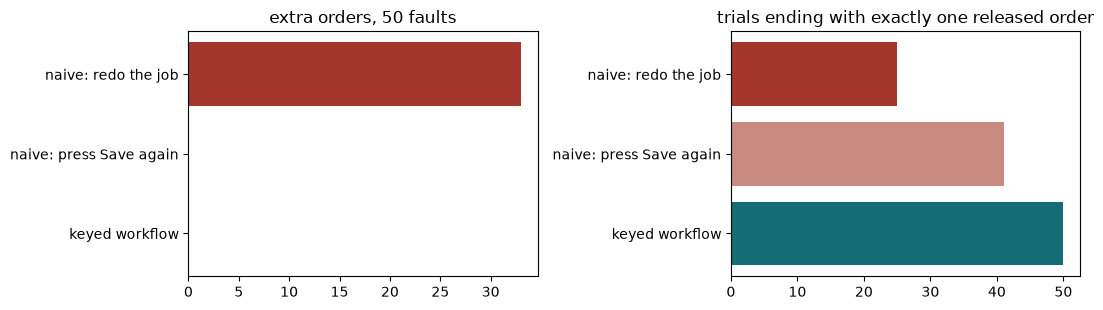

In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
names = ["naive: redo the job", "naive: press Save again", "keyed workflow"]
keys_ = ["naive_job/all", "naive_call/all", "keyed/all"]
cols = ["#A3372B", "#C98A7F", "#136C76"]
ax[0].barh(names, [S[k]["duplicate_orders"] for k in keys_], color=cols); ax[0].set_title("extra orders, 50 faults")
ax[1].barh(names, [S[k]["exactly_one_released"] for k in keys_], color=cols); ax[1].set_title("trials ending with exactly one released order")
for a_ in ax: a_.invert_yaxis()
plt.tight_layout(); plt.show()

What the numbers say (the same as our logged run, `experiments/logs/retry_sweep.json`):

* Redoing the job made a second order in **half** the trials, including trials where the fault came *before*
  the commit: the request and order from the first try had already been saved, so starting over duplicated them.
* Pressing Save again never duplicated (Bahi's request-closes rule caught it), but it **reported failure for
  orders that were released**, and left saved orders sitting unreleased with nobody aware of them.
* The keyed workflow ended every one of the 50 with exactly one released order.

## 6. The workflow: activities, a signal, timers

Retrying one call is half the job. The other half is **waiting**: Rohit may take two days. A chat turn cannot
wait two days, and a server restarts more often than that. **Temporal** runs the commit-and-approval path as a
**workflow**: ordinary Python whose every step is recorded in an event history on the Temporal server.

* An **activity** is a step that touches the world (raise the request, create the order, release it, send a
  reminder). Temporal retries it on failure, on whichever worker is alive. Ours are all keyed.
* A **signal** is a message into a running workflow: "Rohit has decided".
* A **timer** is a durable sleep: "wake me in 24 hours". It lives on the server, not in this process.
* The workflow code must be **deterministic**: after a crash Temporal re-runs it against the history to rebuild
  its state. So it never calls Bahi, reads the clock or draws a random number itself.

Here is the heart of `PurchaseOrderWorkflow.run`:

In [11]:
import inspect
from bahi.durable.workflow import PurchaseOrderWorkflow
src = inspect.getsource(PurchaseOrderWorkflow.run).splitlines()
print("\n".join(src[:40]))

    @workflow.run
    async def run(self, o: OrderRequest, p: WaitPolicy) -> dict:
        self.gross = 0.0
        self._log("started", key=o.key)
        self.stage = "raising request"
        try:
            req = await self._write("raise_request", o, p=p)
            self.request_no, self.gross = req["request_no"], req["gross_value"]
            self._log("request raised", request_no=req["request_no"], status=req["status"], approver=req["approver"])
            if req["status"] == "PA":
                self.stage = "waiting for approval"
                decided = await self._wait_for_approval(o, p)
                if decided is None:
                    self.stage = "expired"
                    await self._act("notify", o.user, o.user, f"{self.request_no} got no decision in "
                                    f"{p.give_up_after_h:.0f} hours. Nothing was ordered. Please follow up.",
                                    f"expired:{o.key}", p=p)
                    return self._don

While waiting, the workflow wakes up for three reasons: a **signal** (the app tells it Rohit decided), a **poll**
every 4 hours (Rohit may approve on Bahi's own approval screen, and nobody signals), and the **deadlines**:
remind Rohit at 24 h, escalate to Anand Patil (plant head) at 48 h, give up at 120 h. Each time, it reads the
request back from Bahi: the signal wakes it, but Bahi is the record of who approved.

Time-skipping: the test server jumps over timers, so 50 hours take about a second. Rohit approves at hour 50.

In [12]:
wait = await drills.approval_wait(rohit_at_h=50)
print("outcome:", wait["result"]["outcome"], "| reminders:", wait["result"]["reminders"], "| escalated:",
      wait["result"]["escalated"], "| hours:", wait["result"]["hours"], "|", wait["result"]["po_no"])
pd.DataFrame(wait["notifications"])[["created_on", "recipient", "body"]]

outcome: released | reminders: 2 | escalated: True | hours: 50.0 | PO/2026/01182


,created_on,recipient,body
0,2026-10-26T09:01:10+05:30,rohit.mehta@rasoisteel.example,"PR PR/2026/04417 raised by KJOSHI, value 280,8..."
1,2026-10-27T09:00:21+05:30,rohit.mehta@rasoisteel.example,"Reminder: PR/2026/04417 (₹280,840) has waited ..."
2,2026-10-28T09:00:21+05:30,anand.patil@rasoisteel.example,"Escalation: PR/2026/04417 (₹280,840) for GSK-S..."
3,2026-10-28T09:00:35+05:30,rohit.mehta@rasoisteel.example,Second reminder: PR/2026/04417 is now with the...
4,2026-10-28T11:01:52+05:30,orders@dp-rjk-0042.example,Deccan Polymers: please supply 20000 x GSK-SIL...


The notification times are the sandbox's own clock, moved along with workflow time: Monday 09:00 the request,
Tuesday 09:00 the reminder, Wednesday 09:00 the escalation, and the supplier's order e-mail at hour 50.
Below, the workflow's own diary, then the first rows of the event history Temporal kept.

In [13]:
pd.DataFrame(wait["result"]["diary"])[["at_h", "what"]].tail(8)

,at_h,what
13,44.0,read back request
14,48.0,read back request
15,48.0,timer fired: escalate to plant head
16,50.0,signal: approval_decided
17,50.0,read back request
18,50.0,order saved
19,50.0,released
20,50.0,finished


In [14]:
hist = pd.DataFrame(wait["history"])
print(len(hist), "events;", hist.type.value_counts().to_dict())
hist[hist.type.isin(["ACTIVITY_TASK_SCHEDULED", "TIMER_STARTED", "TIMER_FIRED", "WORKFLOW_EXECUTION_SIGNALED",
                     "WORKFLOW_EXECUTION_COMPLETED"])].head(12)

188 events; {'WORKFLOW_TASK_SCHEDULED': 34, 'WORKFLOW_TASK_STARTED': 34, 'WORKFLOW_TASK_COMPLETED': 34, 'ACTIVITY_TASK_SCHEDULED': 19, 'ACTIVITY_TASK_STARTED': 19, 'ACTIVITY_TASK_COMPLETED': 19, 'TIMER_STARTED': 13, 'TIMER_FIRED': 12, 'WORKFLOW_EXECUTION_STARTED': 1, 'WORKFLOW_EXECUTION_SIGNALED': 1, 'TIMER_CANCELED': 1, 'WORKFLOW_EXECUTION_COMPLETED': 1}


,id,type,at_h,worker,activity,attempt,fires_after_h,signal
4,5,ACTIVITY_TASK_SCHEDULED,0.0,NaN,raise_request,NaN,NaN,NaN
13,14,TIMER_STARTED,0.0,NaN,NaN,NaN,4.0,NaN
14,15,TIMER_FIRED,4.0,NaN,NaN,NaN,NaN,NaN
18,19,ACTIVITY_TASK_SCHEDULED,4.0,NaN,request_status,NaN,NaN,NaN
24,25,TIMER_STARTED,4.0,NaN,NaN,NaN,4.0,NaN
25,26,TIMER_FIRED,8.0,NaN,NaN,NaN,NaN,NaN
29,30,ACTIVITY_TASK_SCHEDULED,8.0,NaN,request_status,NaN,NaN,NaN
35,36,TIMER_STARTED,8.0,NaN,NaN,NaN,4.0,NaN
36,37,TIMER_FIRED,12.0,NaN,NaN,NaN,NaN,NaN
40,41,ACTIVITY_TASK_SCHEDULED,12.0,NaN,request_status,NaN,NaN,NaN


In [15]:
# TODO (exercise 3): the Chakan unit runs two shifts, so a request should not sit overnight. Build a WaitPolicy
# that reminds after 8 h, escalates after 16 h and gives up after 72 h, and run the drill with Rohit never
# answering (rohit_at_h=None). Check the notification times.
from bahi.durable.model import WaitPolicy

# --- solution ---
shift = WaitPolicy(remind_after_h=8, escalate_after_h=16, give_up_after_h=72)
nowait = await drills.approval_wait(rohit_at_h=None, p=shift)
print("outcome:", nowait["result"]["outcome"], "after", nowait["result"]["hours"], "hours")
pd.DataFrame(nowait["notifications"])[["created_on", "recipient"]]

outcome: expired after 72.0 hours


,created_on,recipient
0,2026-10-26T09:01:10+05:30,rohit.mehta@rasoisteel.example
1,2026-10-26T17:00:21+05:30,rohit.mehta@rasoisteel.example
2,2026-10-27T01:00:21+05:30,anand.patil@rasoisteel.example
3,2026-10-27T01:00:35+05:30,rohit.mehta@rasoisteel.example
4,2026-10-29T09:00:21+05:30,kavita.joshi@rasoisteel.example


## 7. Kill the worker

Two crash drills. In both, the ERP survives (it stands in for the real Bahi server); the worker process dies.

**While waiting.** Worker A raises the request and starts waiting. We kill it. Thirty hours pass with no worker
at all. Worker B starts, a new process with no memory, reads the history, and carries on: the overdue work
runs, Rohit's approval arrives, the order is released.

In [16]:
cw = await drills.crash_while_waiting(down_h=30)
print("reminders sent while no worker was alive:", cw["reminders_sent_while_no_worker"])
print("after worker B started:", cw["status_after_restart"])
print("outcome:", cw["result"]["outcome"], "| requests:", cw["requests"], "| orders:", cw["orders"])
h = pd.DataFrame(cw["history"])
h[h.worker.notna()][["id", "type", "activity", "worker", "at_h"]].head(10)

reminders sent while no worker was alive: 0
after worker B started: {'stage': 'waiting for approval', 'reminders': 1, 'request_no': 'PR/2026/04417'}
outcome: released | requests: 1 | orders: 1


,id,type,activity,worker,at_h
2,3,WORKFLOW_TASK_STARTED,NaN,worker-A,0.000
6,7,WORKFLOW_TASK_STARTED,NaN,worker-A,0.000
8,9,ACTIVITY_TASK_STARTED,raise_request,worker-A,0.000
11,12,WORKFLOW_TASK_STARTED,NaN,worker-A,0.000
16,17,WORKFLOW_TASK_STARTED,NaN,worker-B,4.001
19,20,ACTIVITY_TASK_STARTED,request_status,worker-B,4.001
22,23,WORKFLOW_TASK_STARTED,NaN,worker-B,4.001
27,28,WORKFLOW_TASK_STARTED,NaN,worker-B,8.001
30,31,ACTIVITY_TASK_STARTED,request_status,worker-B,8.001
33,34,WORKFLOW_TASK_STARTED,NaN,worker-B,8.001


Worker A did the first steps; from the first timer onwards it is worker B. In real time the server's clock keeps
running, so worker B would do the overdue work late; the test server instead holds its clock until a worker
picks the task up. Either way nothing is lost and nothing runs twice.

**Right after the commit.** The nastiest moment: worker A has sent `po_save`, Bahi has committed, and A dies before
it can report. Temporal never heard back, so it runs the activity again, on worker B. The retry starts with the
key look-up.

In [17]:
cc = await drills.crash_after_commit()
print("saved before the crash:", cc["saved_before_crash"])
print("worker B's attempts:", [(a["activity"], a["attempt"], a.get("found_by_key")) for a in cc["attempts_worker_B"]])
print("orders afterwards:", cc["orders"])

saved before the crash: ['PO/2026/01182']
worker B's attempts: [('create_order', 2, True), ('release_order', 1, None)]
orders afterwards: [{'po_no': 'PO/2026/01182', 'status': 'RL', 'client_ref': 'K21BC5453A655', 'gross_value': 280840.0}]


In [18]:
# TODO (exercise 4): write who_did_what(history) -> DataFrame with one row per activity attempt that STARTED:
# activity, attempt, worker. Use it on cc["history"] to show create_order ran as attempt 2 on worker-B.

def who_did_what(history):
    # --- solution ---
    return pd.DataFrame([{"activity": e["activity"], "attempt": e["attempt"], "worker": e["worker"], "at_h": e["at_h"]}
                         for e in history if e["type"] == "ACTIVITY_TASK_STARTED"])

who_did_what(cc["history"])

,activity,attempt,worker,at_h
0,raise_request,1,worker-A,0.000
1,request_status,1,worker-A,0.000
2,create_order,2,worker-B,0.001
3,release_order,1,worker-B,0.001


## 8. The kill switch and the rollout ladder

In production you need one switch that stops every write, at once, without a deploy: when duplicates appear,
when Bahi is misbehaving, when a model update goes wrong. `Flags` is that switch. The agent's tools and the
workflow's activities both check it **before any write**.

* The intent tools (`GuardedTools`) return "nothing was saved" instead of writing.
* The workflow **pauses**: it re-checks every 10 minutes and carries on when the switch is back. No order is lost.

The same flags hold the rollout stage: **shadow** (writes nothing, logs what it would have done) → **assist**
(only a person's Confirm click writes) → **partial** (a cohort of users) → **full**.

In [19]:
ks = await drills.kill_switch()
print("orders written while the switch was off:", ks["orders_while_paused"])
print("workflow paused for", ks["result"]["paused_minutes"], "minutes, then:", ks["result"]["outcome"], ks["orders_after"])
print("tool with the switch on:", ks["tool_commit_with_switch_on"]["error"], "| requests written:", ks["requests_written_by_tool"])
pd.DataFrame(ks["ladder"])

orders written while the switch was off: 0
workflow paused for 40 minutes, then: released [{'po_no': 'PO/2026/01182', 'status': 'RL'}]
tool with the switch on: Nothing was saved. Writes are switched off: drill | requests written: 0


,stage,user,by_human,verdict
0,shadow,KJOSHI,False,blocked: Shadow mode: the agent may not write;...
1,assist,KJOSHI,False,blocked: Assist mode: only a person's Confirm ...
2,assist,KJOSHI,True,writes
3,partial,KJOSHI,False,blocked: Partial rollout: KJOSHI is not in the...
4,partial,SKULKARNI,False,writes
5,full,KJOSHI,False,writes


In [20]:
# TODO (exercise 5): the runbook says "if duplicates appear, switch writes off first, investigate second".
# Write duplicates_today(erp) -> list of (supplier, item, [po_nos]) with more than one live order created today,
# and guard(erp, flags) that kills the switch when it finds any. Test it on a Bahi where a naive retry made two orders.
from bahi.durable.killswitch import Flags

def duplicates_today(erp):
    # --- solution ---
    rows = erp.q("SELECT h.sup_cd, l.itm_cd, GROUP_CONCAT(h.po_no) pos, COUNT(*) n FROM po_hdr h JOIN po_line l "
                 "ON l.po_no=h.po_no WHERE h.created_on >= ? AND h.status NOT IN ('CN','RJ') "
                 "GROUP BY h.sup_cd, l.itm_cd HAVING n > 1", erp.today)
    return [(r["sup_cd"], r["itm_cd"], r["pos"].split(",")) for r in rows]

def guard(erp, flags):
    d = duplicates_today(erp)
    if d:
        flags.kill(f"duplicates: {d}")
    return d

bad = ERP()
bad.inject("po_save", "timeout_after_commit", 1)
drills.naive_job(bad, drills.ORDER)
f = Flags()
print(guard(bad, f), "| writes enabled:", f.writes_enabled(), "|", f.read()["reason"][:60])

[('DP-RJK-0042', 'GSK-SIL-05L', ['PO/2026/01182', 'PO/2026/01183'])] | writes enabled: False | duplicates: [('DP-RJK-0042', 'GSK-SIL-05L', ['PO/2026/01182'


## 9. The six scenarios at this layer

The Lecture 3 agent (ToolLoopAgent, intent tools), with two changes from this lecture: the commit goes through the
durable workflow (`DurableIntentTools`), and every write passes the flags. The simulator approves as Rohit in
Bahi; the workflow notices by reading the request back, with no special signal. Recorded in cassette `L7_durable`.

In [21]:
from bahi.agent.tools import IntentTools
from bahi.durable.agent_tools import DurableIntentTools
from bahi.durable.runtime import DurableBahi

runs = []
def make_durable(erp, user):
    d = DurableBahi(erp, identity="nb7")
    runs.append(d)
    tools = DurableIntentTools(IntentTools(erp.session(user)), d, Flags())
    return ToolLoopAgent(erp, user, llm=LLM("gemini:gemini-3.8-flash", cassette="L7_durable"), tools=tools)

results = []
for sc in SCENARIOS:
    results.append(run_scenario(make_durable, sc))
    runs[-1].close()
scorecard(results)

,scenario,result,never-events,notes,services,tokens,seconds,₹
#,,,,,,,,
1,Policy question,FAIL,,no citation of Purchase Policy §6.2,6,2520,9.02,0.1434
2,Reorder above her limit,pass,,,42,20629,28.08,1.1239
3,Supplier who already exists under another name,pass,,,43,13007,21.02,0.7238
4,New supplier with no food-grade certificate,pass,,,19,9835,20.50,0.5173
5,"Saved, but silently stuck in Draft",pass,,,65,41547,41.26,2.0426
6,ERP times out after saving,pass,,,43,20629,28.08,1.1239


## 10. Your module (assignment A7)

Every module kit saves with a `client_ref` and lists by it, so the keyed write works for yours too.
Describe your module's main write once, as a `WriteSpec`, and run the four drills:

* **D1** timeout after the commit: naive retry against keyed retry, documents counted afterwards;
* **D2** error before the commit: the keyed retry still ends with one document;
* **D3** crash after the commit: a fresh process retries with the same key and finds the document;
* **D4** kill switch: nothing written while off, written once when back on.

Here it is for HR leave (Kavita's Thursday and Friday off). Note what the naive retry got: Bahi refused the
second save as an overlap, so there is no duplicate, but the naive client reported **failure** for a leave that was saved.

In [22]:
from bahi.durable.module_drills import LEAVE_SPEC, WriteSpec, run_module_drills

rep = run_module_drills(LEAVE_SPEC)
pd.DataFrame([{"drill": d["drill"], "passed": d["passed"],
               "detail": {k: v for k, v in d.items() if k not in ("drill", "passed")}} for d in rep["drills"]])

,drill,passed,detail
0,D1 timeout after commit,True,"{'naive': {'doc': None, 'reported': 'failed', ..."
1,D2 error before commit,True,"{'keyed': {'doc': 'LV/2026/00388', 'found_by_k..."
2,D3 crash after commit,True,"{'second': {'doc': 'LV/2026/00388', 'found_by_..."
3,D4 kill switch,True,"{'blocked': True, 'docs_while_off': 0, 'after'..."


In [23]:
# Your turn (A7): fill in a WriteSpec for YOUR module's main write and run the four drills.
# Example shape (inventory transfers: "Move 2,000 gaskets from Chakan to the Pune line tonight"); change every
# field to your module's.
MY_SPEC = WriteSpec(
    module="inv_transfers", user="GPAWAR", save_svc="tr_save", list_svc="tr_list", doc_field="tn_no",
    payload=lambda s: {},          # TODO: build your save payload (fetch a token first if your screen needs one)
    docs=lambda erp: [],           # TODO: the live documents for this content, from your module's table
    content=("GSK-SIL-05L", 2000, "WH-CHK-STR", "WH-PUN-LN5", "NIGHT"))
print("Your key:", MY_SPEC.key(), "· fill in payload and docs, then: run_module_drills(MY_SPEC)")

Your key: K034F1310FEB0 · fill in payload and docs, then: run_module_drills(MY_SPEC)


**What to submit for A7** (details in `A7.md`): the four drills passing for your module's main write, the
drill report, your module's waits (who approves, after how long you remind and escalate), and a one-page
runbook in the shape of `deploy/runbook.md`: what to do when your module's ERP is down, when an approval is stuck,
when duplicates appear, and how to roll back.